# House Prices - Data Cleaning, EDA, dan Data Splitting

## Tahap 1 - Data Cleaning & Transformation

In [1]:
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt
from sklearn.preprocessing import StandardScaler, LabelEncoder
from sklearn.model_selection import train_test_split

In [2]:
train = pd.read_csv("train.csv")
test = pd.read_csv("test.csv")
train.head()

,Id,MSSubClass,MSZoning,LotFrontage,LotArea,Street,Alley,LotShape,LandContour,Utilities,...,PoolArea,PoolQC,Fence,MiscFeature,MiscVal,MoSold,YrSold,SaleType,SaleCondition,SalePrice
0,1,60,RL,65.0,8450,Pave,NaN,Reg,Lvl,AllPub,...,0,NaN,NaN,NaN,0,2,2008,WD,Normal,208500
1,2,20,RL,80.0,9600,Pave,NaN,Reg,Lvl,AllPub,...,0,NaN,NaN,NaN,0,5,2007,WD,Normal,181500
2,3,60,RL,68.0,11250,Pave,NaN,IR1,Lvl,AllPub,...,0,NaN,NaN,NaN,0,9,2008,WD,Normal,223500
3,4,70,RL,60.0,9550,Pave,NaN,IR1,Lvl,AllPub,...,0,NaN,NaN,NaN,0,2,2006,WD,Abnorml,140000
4,5,60,RL,84.0,14260,Pave,NaN,IR1,Lvl,AllPub,...,0,NaN,NaN,NaN,0,12,2008,WD,Normal,250000


In [3]:
train.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1460 entries, 0 to 1459
Data columns (total 81 columns):
Id               1460 non-null int64
MSSubClass       1460 non-null int64
MSZoning         1460 non-null object
LotFrontage      1201 non-null float64
LotArea          1460 non-null int64
Street           1460 non-null object
Alley            91 non-null object
LotShape         1460 non-null object
LandContour      1460 non-null object
Utilities        1460 non-null object
LotConfig        1460 non-null object
LandSlope        1460 non-null object
Neighborhood     1460 non-null object
Condition1       1460 non-null object
Condition2       1460 non-null object
BldgType         1460 non-null object
HouseStyle       1460 non-null object
OverallQual      1460 non-null int64
OverallCond      1460 non-null int64
YearBuilt        1460 non-null int64
YearRemodAdd     1460 non-null int64
RoofStyle        1460 non-null object
RoofMatl         1460 non-null object
Exterior1st      1460 non-n

In [4]:
train.describe(include="all")

,Id,MSSubClass,MSZoning,LotFrontage,LotArea,Street,Alley,LotShape,LandContour,Utilities,...,PoolArea,PoolQC,Fence,MiscFeature,MiscVal,MoSold,YrSold,SaleType,SaleCondition,SalePrice
count,1460.000000,1460.000000,1460,1201.000000,1460.000000,1460,91,1460,1460,1460,...,1460.000000,7,281,54,1460.000000,1460.000000,1460.000000,1460,1460,1460.000000
unique,NaN,NaN,5,NaN,NaN,2,2,4,4,2,...,NaN,3,4,4,NaN,NaN,NaN,9,6,NaN
top,NaN,NaN,RL,NaN,NaN,Pave,Grvl,Reg,Lvl,AllPub,...,NaN,Gd,MnPrv,Shed,NaN,NaN,NaN,WD,Normal,NaN
freq,NaN,NaN,1151,NaN,NaN,1454,50,925,1311,1459,...,NaN,3,157,49,NaN,NaN,NaN,1267,1198,NaN
mean,730.500000,56.897260,NaN,70.049958,10516.828082,NaN,NaN,NaN,NaN,NaN,...,2.758904,NaN,NaN,NaN,43.489041,6.321918,2007.815753,NaN,NaN,180921.195890
std,421.610009,42.300571,NaN,24.284752,9981.264932,NaN,NaN,NaN,NaN,NaN,...,40.177307,NaN,NaN,NaN,496.123024,2.703626,1.328095,NaN,NaN,79442.502883
min,1.000000,20.000000,NaN,21.000000,1300.000000,NaN,NaN,NaN,NaN,NaN,...,0.000000,NaN,NaN,NaN,0.000000,1.000000,2006.000000,NaN,NaN,34900.000000
25%,365.750000,20.000000,NaN,59.000000,7553.500000,NaN,NaN,NaN,NaN,NaN,...,0.000000,NaN,NaN,NaN,0.000000,5.000000,2007.000000,NaN,NaN,129975.000000
50%,730.500000,50.000000,NaN,69.000000,9478.500000,NaN,NaN,NaN,NaN,NaN,...,0.000000,NaN,NaN,NaN,0.000000,6.000000,2008.000000,NaN,NaN,163000.000000
75%,1095.250000,70.000000,NaN,80.000000,11601.500000,NaN,NaN,NaN,NaN,NaN,...,0.000000,NaN,NaN,NaN,0.000000,8.000000,2009.000000,NaN,NaN,214000.000000


In [5]:
missing_values = train.isnull().sum()
missing_values[missing_values > 0]

LotFrontage      259
Alley           1369
MasVnrType         8
MasVnrArea         8
BsmtQual          37
BsmtCond          37
BsmtExposure      38
BsmtFinType1      37
BsmtFinType2      38
Electrical         1
FireplaceQu      690
GarageType        81
GarageYrBlt       81
GarageFinish      81
GarageQual        81
GarageCond        81
PoolQC          1453
Fence           1179
MiscFeature     1406
dtype: int64

In [6]:
less = missing_values[missing_values < 1000].index
over = missing_values[missing_values >= 1000].index

In [7]:
numeric_features = train[less].select_dtypes(include=["number"]).columns
train[numeric_features] = train[numeric_features].fillna(train[numeric_features].median())

In [8]:
categorical_features = train[less].select_dtypes(include=["object"]).columns
for column in categorical_features:
    train[column] = train[column].fillna(train[column].mode()[0])

In [9]:
df = train.drop(columns=over)
missing_values = df.isnull().sum()
missing_values[missing_values > 0]

Series([], dtype: int64)

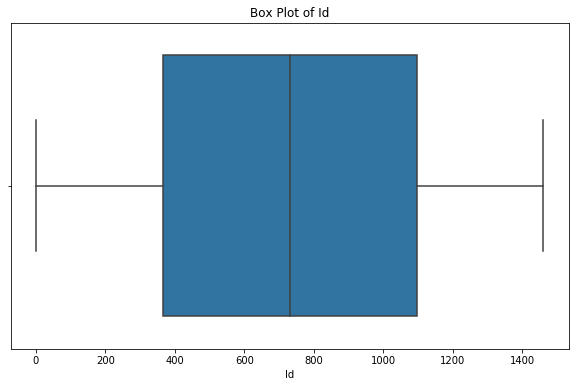

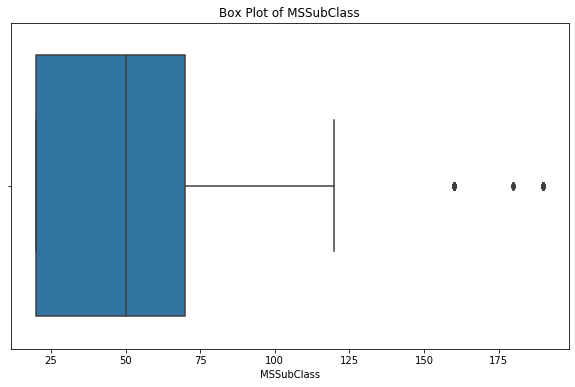

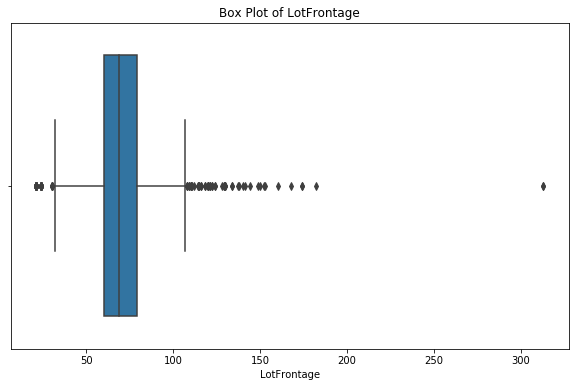

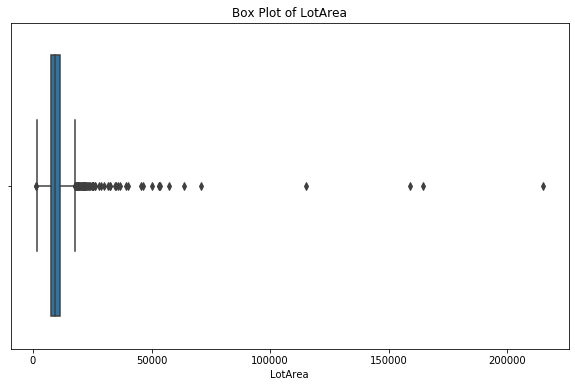

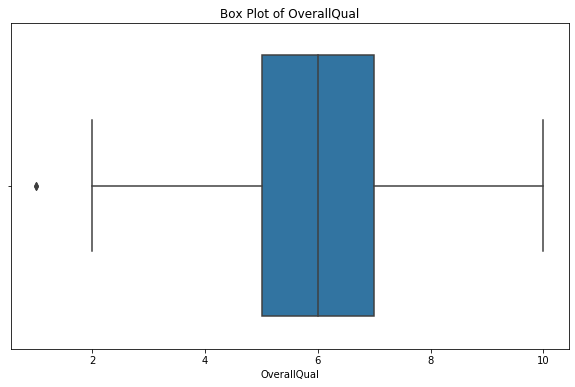

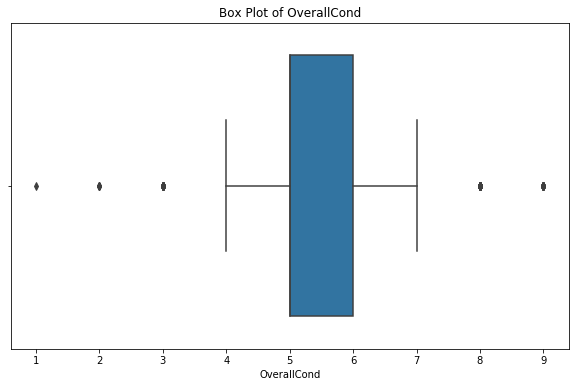

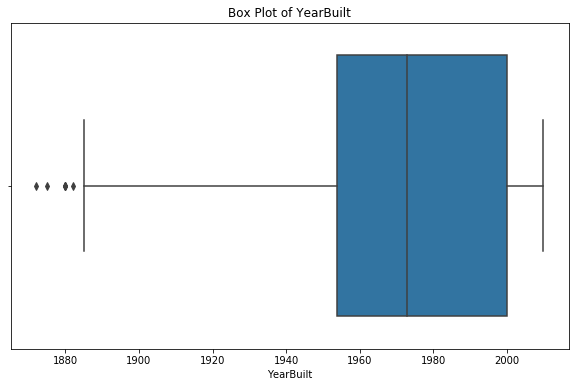

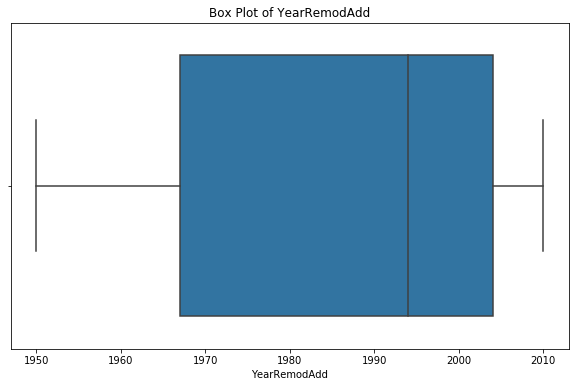

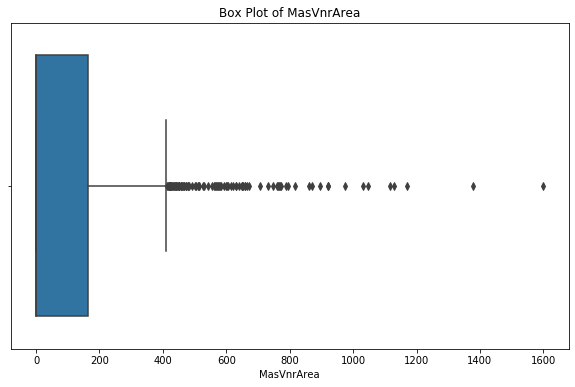

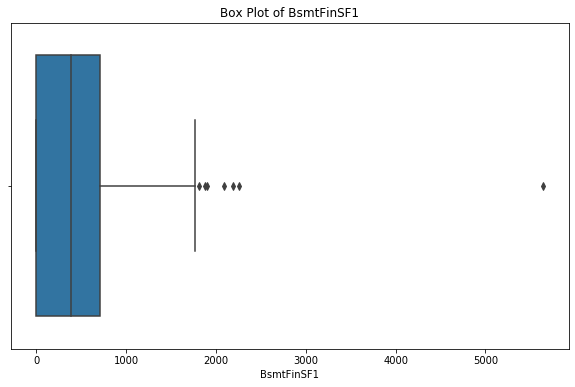

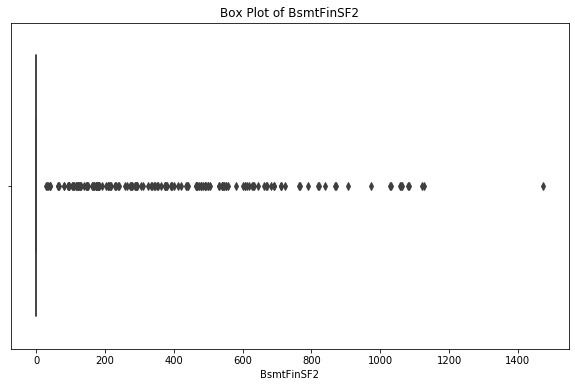

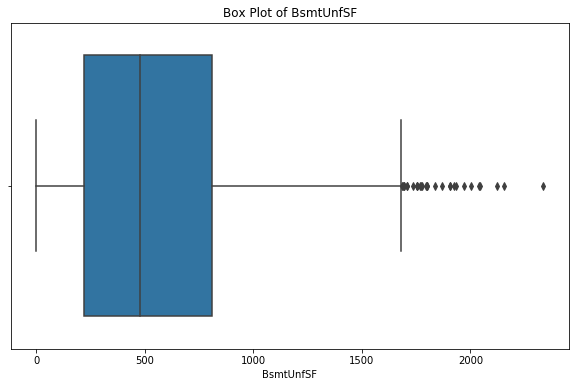

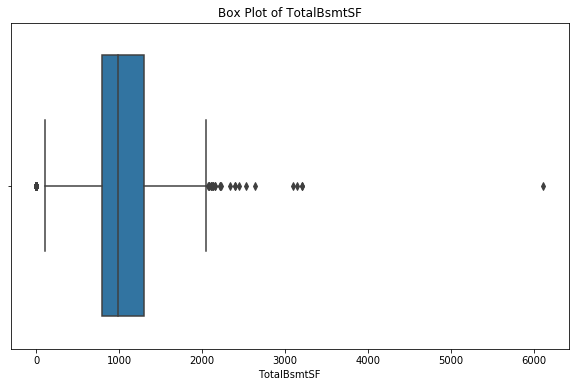

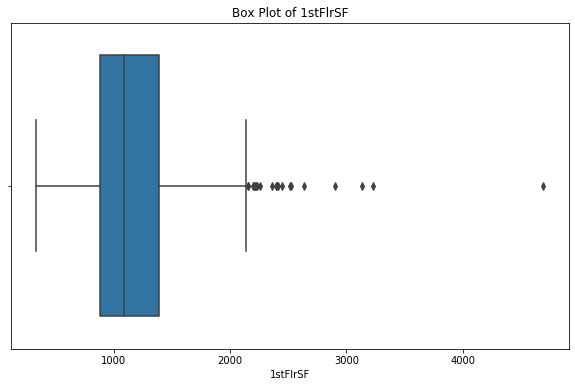

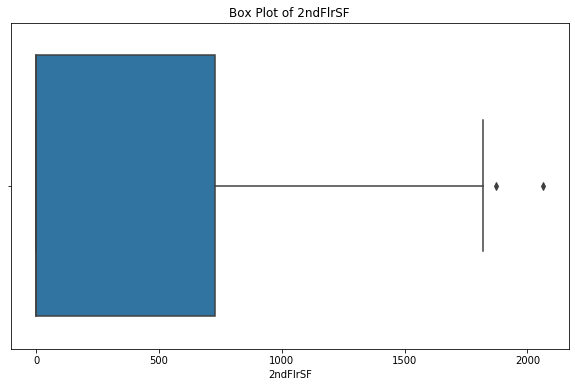

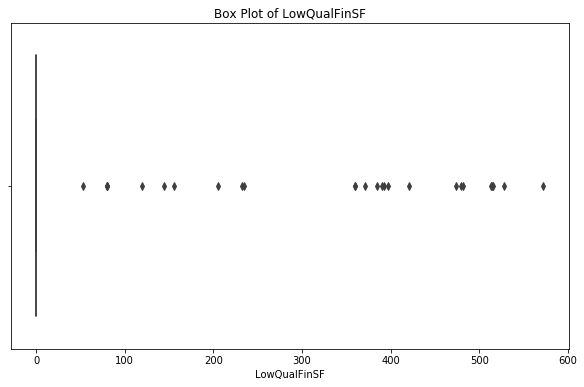

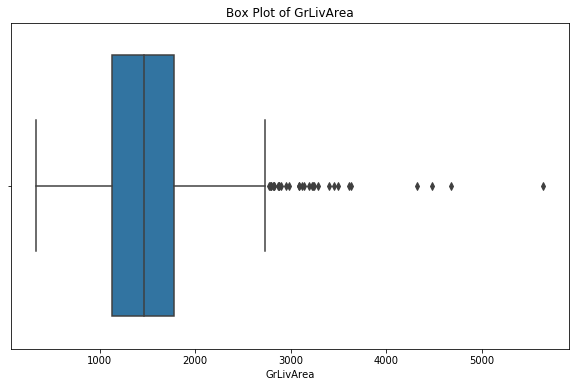

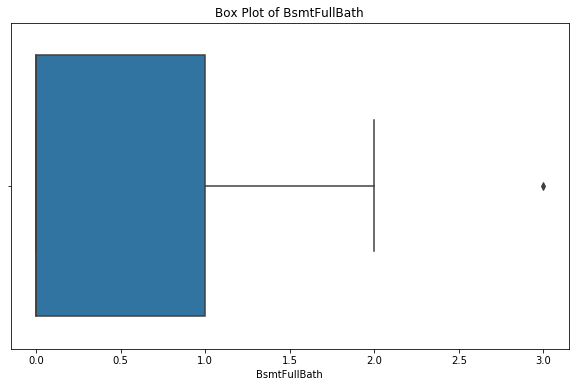

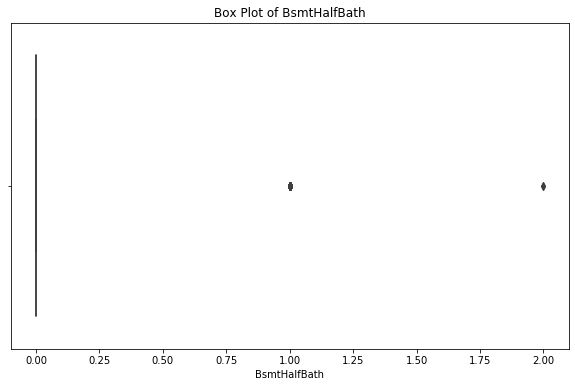

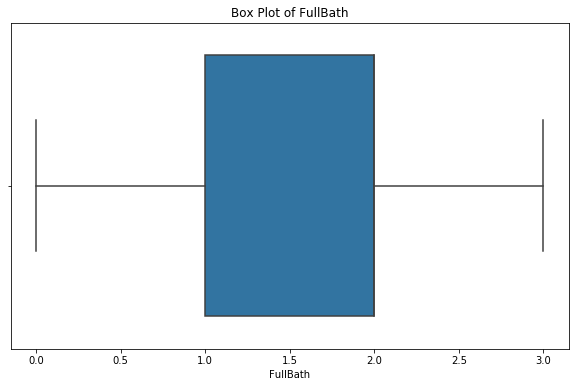

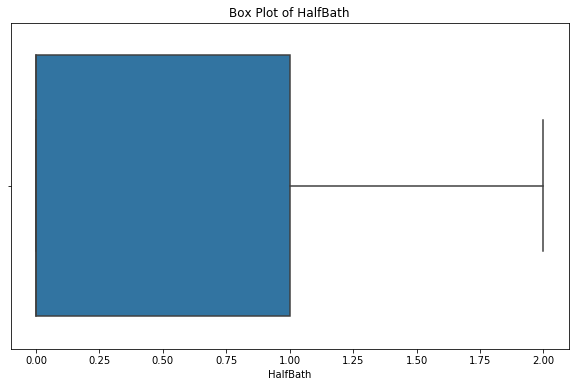

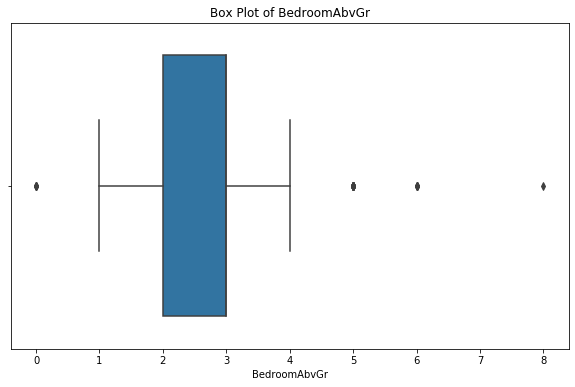

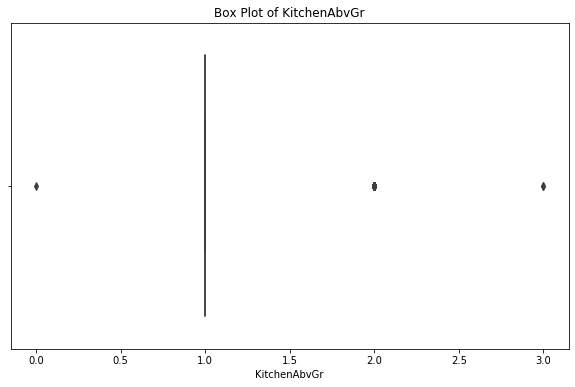

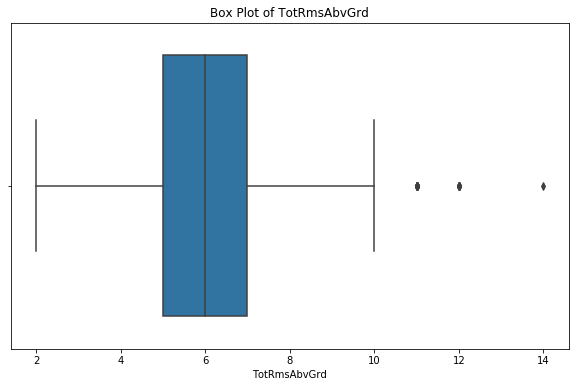

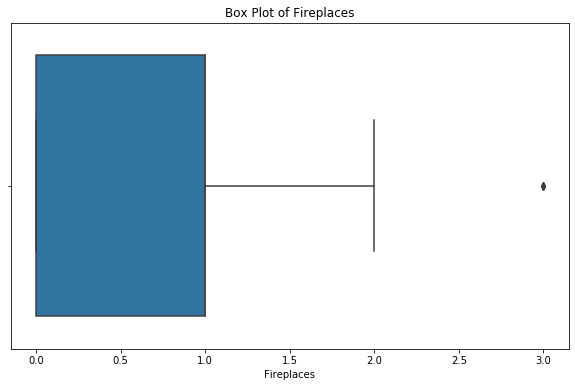

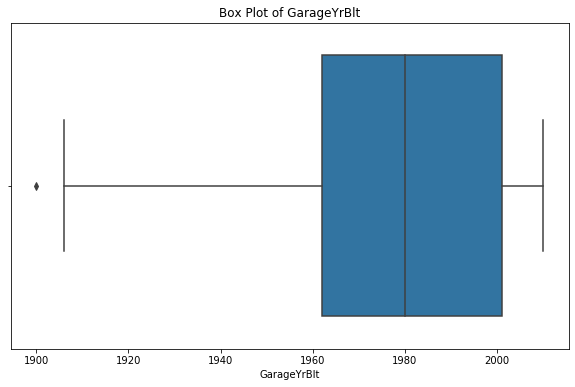

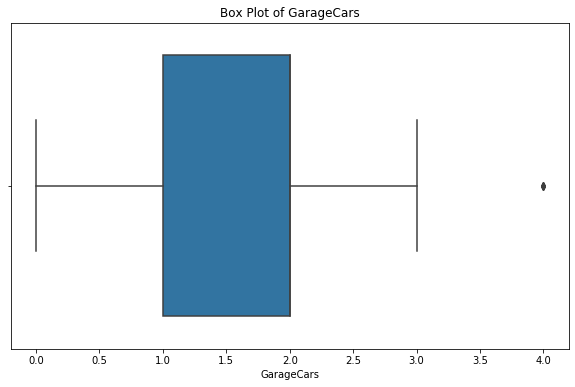

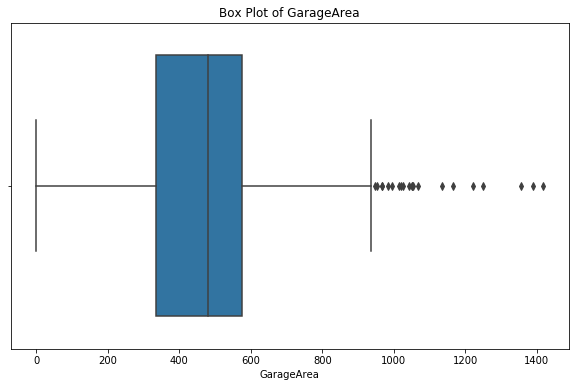

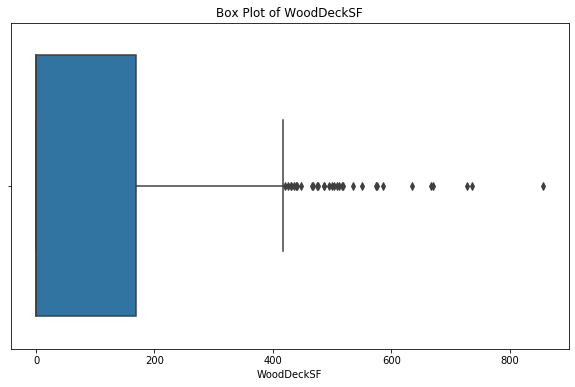

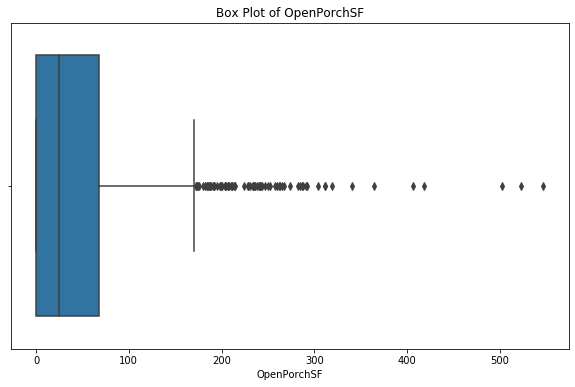

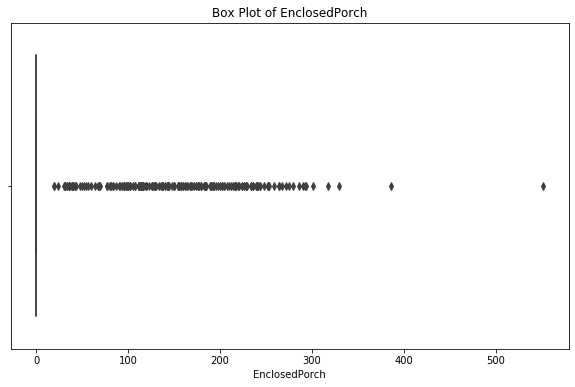

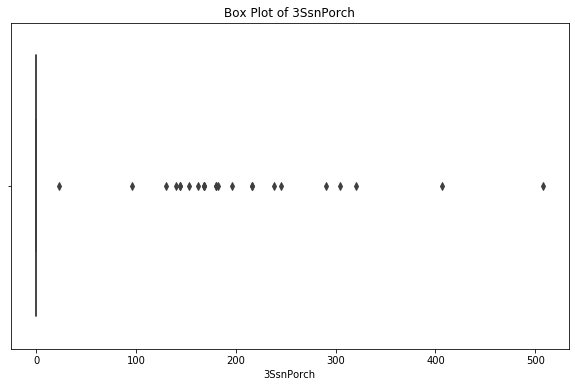

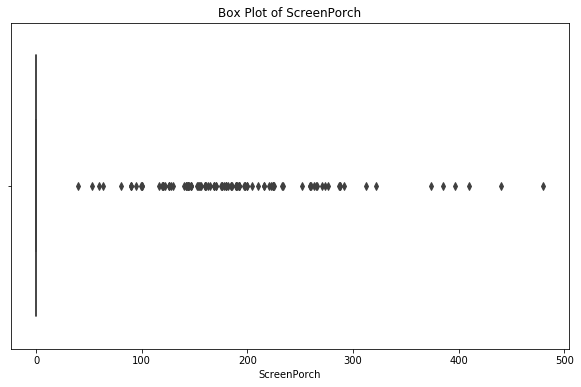

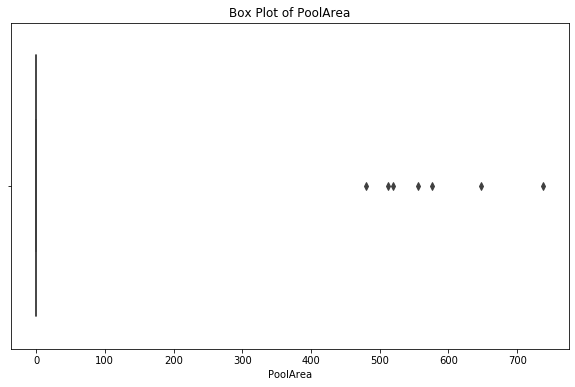

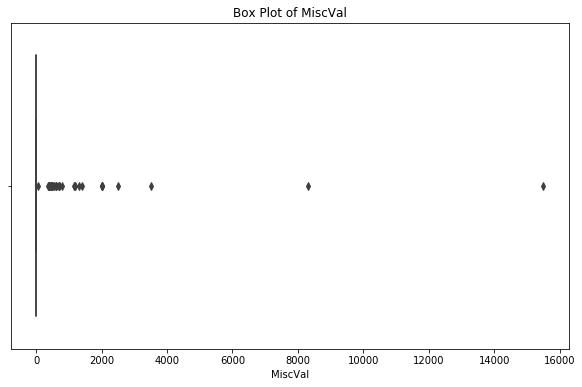

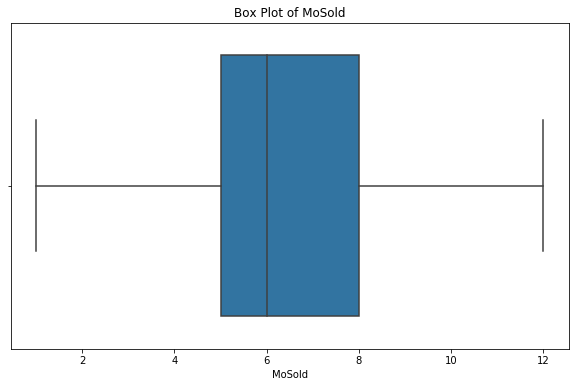

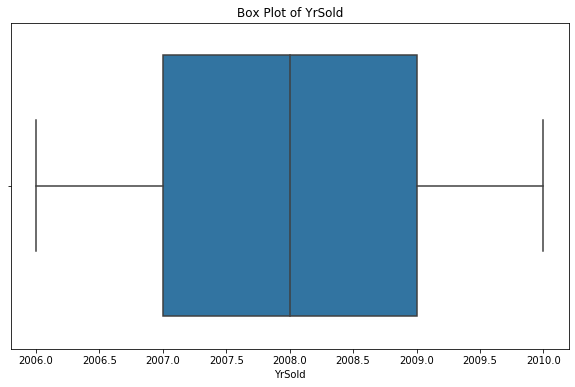

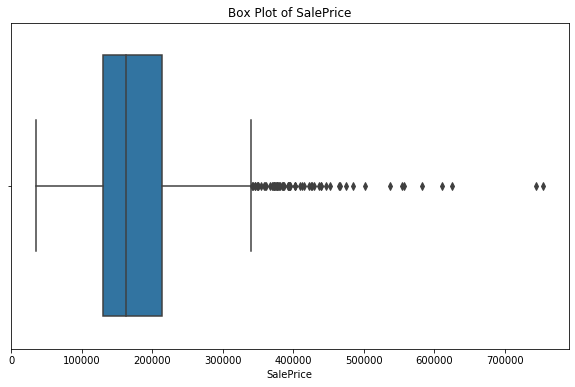

In [10]:
for feature in numeric_features:
    plt.figure(figsize=(10,6))
    sns.boxplot(x=df[feature])
    plt.title(f"Box Plot of {feature}")
    plt.show()

In [11]:
Q1 = df[numeric_features].quantile(0.25)
Q3 = df[numeric_features].quantile(0.75)
IQR = Q3 - Q1

condition = ~((df[numeric_features] < (Q1 - 1.5*IQR)) |
              (df[numeric_features] > (Q3 + 1.5*IQR))).any(axis=1)

df_filtered_numeric = df.loc[condition, numeric_features]
categorical_features = df.select_dtypes(include=["object"]).columns
df = pd.concat([df_filtered_numeric, df.loc[condition, categorical_features]], axis=1)

In [12]:
scaler = StandardScaler()
df[numeric_features] = scaler.fit_transform(df[numeric_features])

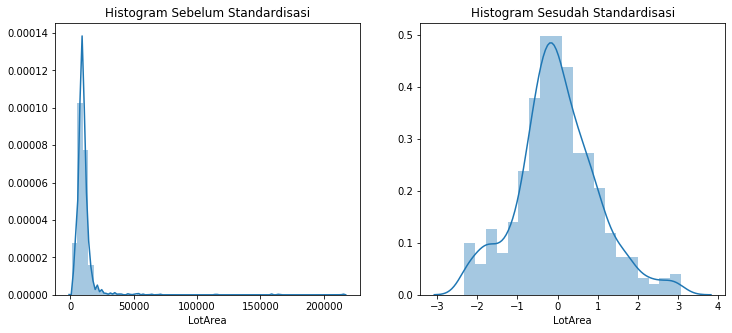

In [13]:
plt.figure(figsize=(12,5))
plt.subplot(1,2,1)
sns.distplot(train[numeric_features[3]], kde=True)
plt.title("Histogram Sebelum Standardisasi")

plt.subplot(1,2,2)
sns.distplot(df[numeric_features[3]], kde=True)
plt.title("Histogram Sesudah Standardisasi")
plt.show()

In [14]:
duplicates = df.duplicated()
print(df[duplicates])
df = df.drop_duplicates()

Empty DataFrame
Columns: [Id, MSSubClass, LotFrontage, LotArea, OverallQual, OverallCond, YearBuilt, YearRemodAdd, MasVnrArea, BsmtFinSF1, BsmtFinSF2, BsmtUnfSF, TotalBsmtSF, 1stFlrSF, 2ndFlrSF, LowQualFinSF, GrLivArea, BsmtFullBath, BsmtHalfBath, FullBath, HalfBath, BedroomAbvGr, KitchenAbvGr, TotRmsAbvGrd, Fireplaces, GarageYrBlt, GarageCars, GarageArea, WoodDeckSF, OpenPorchSF, EnclosedPorch, 3SsnPorch, ScreenPorch, PoolArea, MiscVal, MoSold, YrSold, SalePrice, MSZoning, Street, LotShape, LandContour, Utilities, LotConfig, LandSlope, Neighborhood, Condition1, Condition2, BldgType, HouseStyle, RoofStyle, RoofMatl, Exterior1st, Exterior2nd, MasVnrType, ExterQual, ExterCond, Foundation, BsmtQual, BsmtCond, BsmtExposure, BsmtFinType1, BsmtFinType2, Heating, HeatingQC, CentralAir, Electrical, KitchenQual, Functional, FireplaceQu, GarageType, GarageFinish, GarageQual, GarageCond, PavedDrive, SaleType, SaleCondition]
Index: []

[0 rows x 77 columns]


In [15]:
category_features = df.select_dtypes(include=["object"]).columns
label_encoder = LabelEncoder()
df_lencoder = pd.DataFrame(df)
for col in category_features:
    df_lencoder[col] = label_encoder.fit_transform(df[col])
df_lencoder.head()

,Id,MSSubClass,LotFrontage,LotArea,OverallQual,OverallCond,YearBuilt,YearRemodAdd,MasVnrArea,BsmtFinSF1,...,KitchenQual,Functional,FireplaceQu,GarageType,GarageFinish,GarageQual,GarageCond,PavedDrive,SaleType,SaleCondition
0,-1.768952,0.356986,-0.265012,-0.284244,0.614520,-0.523677,0.784193,0.704506,1.183911,0.639427,...,2,4,2,0,1,2,3,2,8,3
2,-1.764179,0.356986,-0.037099,0.744924,0.614520,-0.523677,0.704296,0.653431,0.856804,0.101006,...,2,4,4,0,1,2,3,2,8,3
4,-1.759405,0.356986,1.178437,1.851281,1.419903,-0.523677,0.664347,0.551281,2.665515,0.514611,...,2,4,4,0,1,2,3,2,8,3
6,-1.754632,-0.917637,0.494698,0.316349,1.419903,-0.523677,0.824141,0.806656,1.087703,2.262035,...,2,4,2,0,1,2,3,2,8,3
10,-1.745085,-0.917637,0.114843,0.726546,-0.996245,-0.523677,-0.733845,-1.236347,-0.701766,1.128902,...,3,4,2,3,2,2,3,2,8,3


## Tahap 2 - Exploratory & Explanatory Data Analysis

In [16]:
missing_values = df_lencoder.isnull().sum()
missing_percentage = (missing_values / len(df_lencoder)) * 100
missing_data = pd.DataFrame({
    "Missing Values": missing_values,
    "Percentage": missing_percentage
}).sort_values(by="Missing Values", ascending=False)
missing_data[missing_data["Missing Values"] > 0]

,Missing Values,Percentage


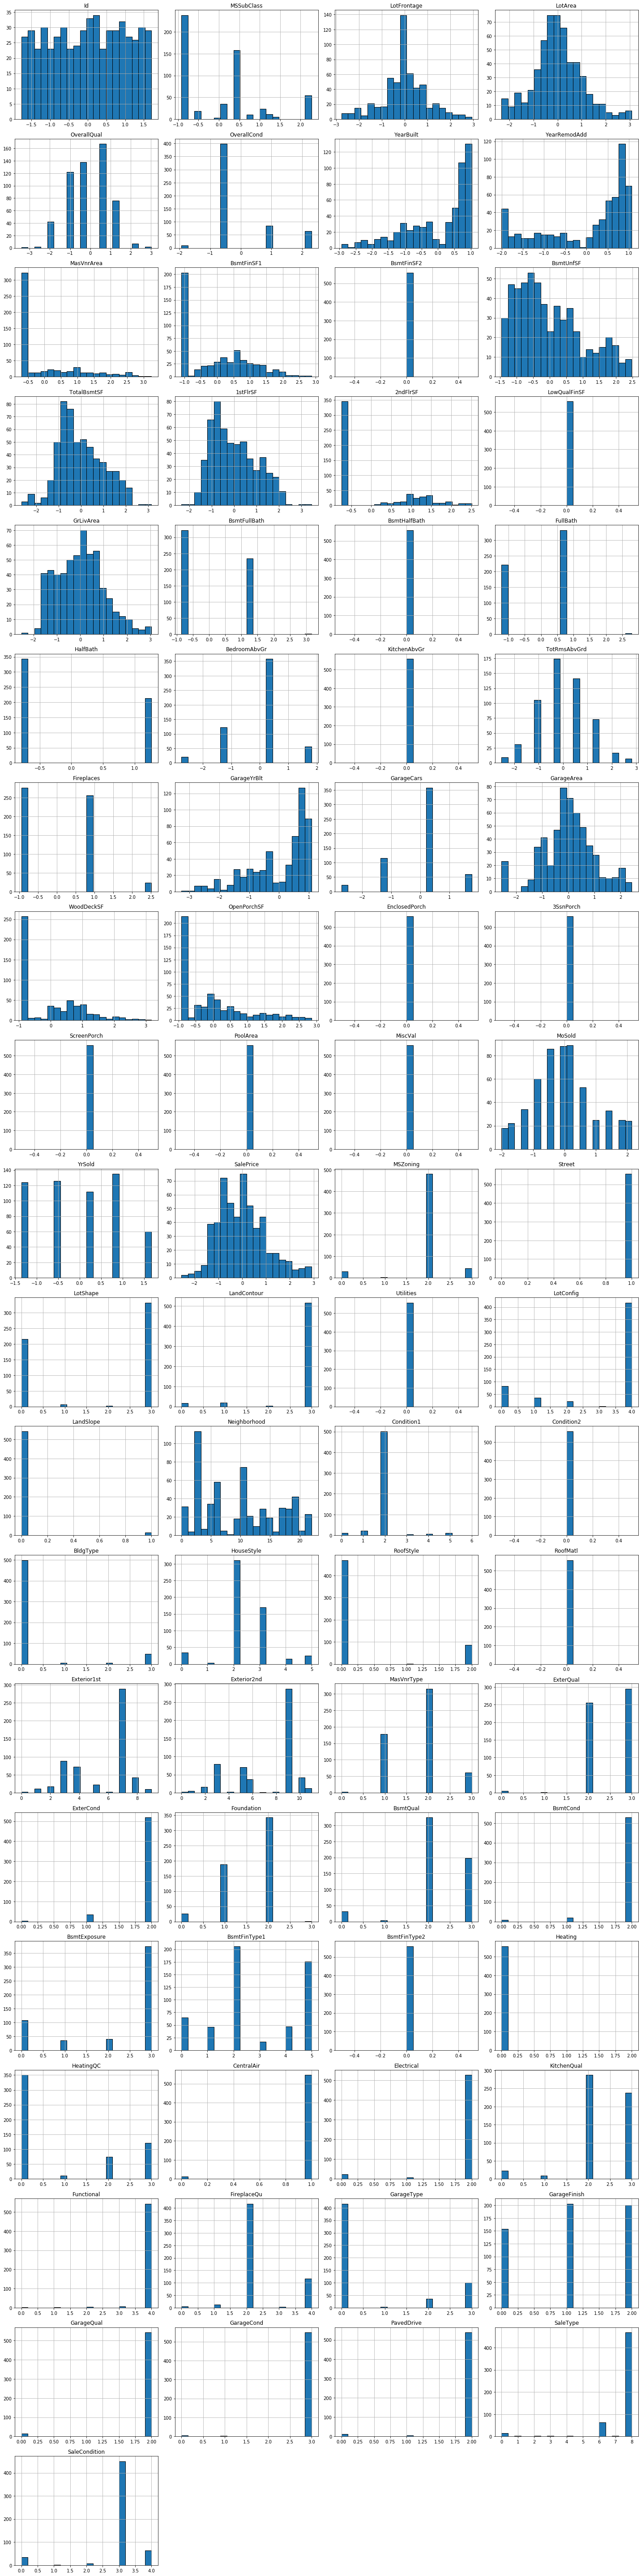

In [17]:
num_vars = df_lencoder.shape[1]
n_cols = 4
n_rows = -(-num_vars // n_cols)
fig, axes = plt.subplots(n_rows, n_cols, figsize=(20, n_rows*4))
axes = axes.flatten()

for i, column in enumerate(df_lencoder.columns):
    df_lencoder[column].hist(ax=axes[i], bins=20, edgecolor="black")
    axes[i].set_title(column)

for j in range(i+1, len(axes)):
    fig.delaxes(axes[j])

plt.tight_layout()
plt.show()

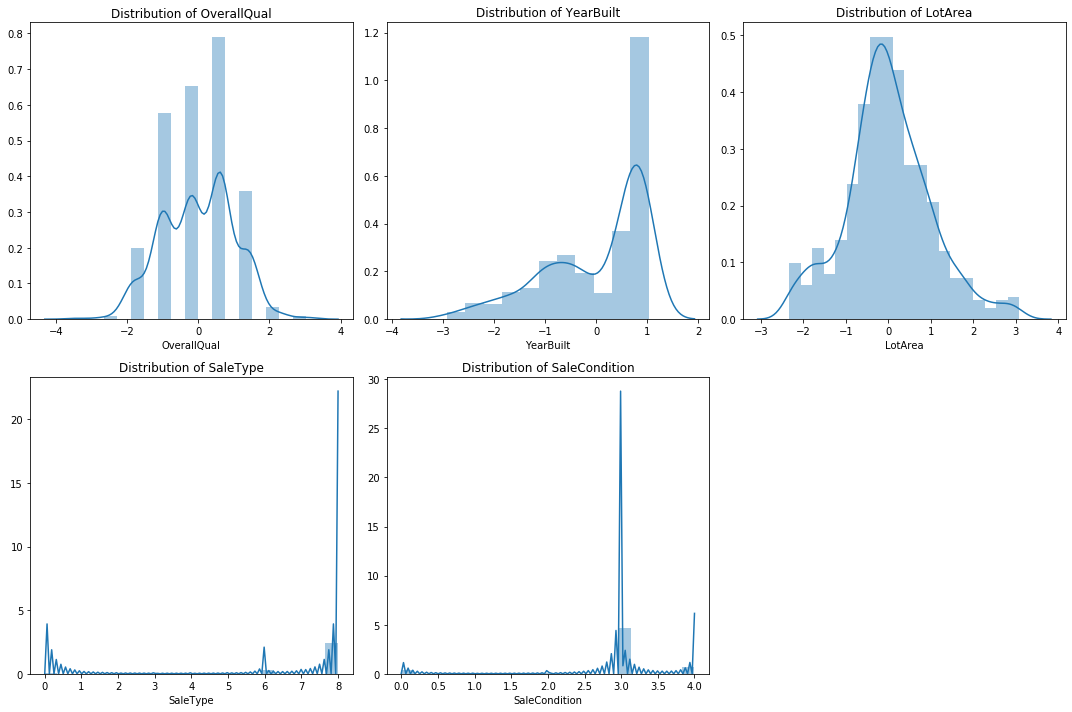

In [18]:
columns_to_plot = ["OverallQual","YearBuilt","LotArea","SaleType","SaleCondition"]

plt.figure(figsize=(15,10))
for i, column in enumerate(columns_to_plot,1):
    plt.subplot(2,3,i)
    sns.distplot(df_lencoder[column], kde=True)
    plt.title(f"Distribution of {column}")
plt.tight_layout()
plt.show()

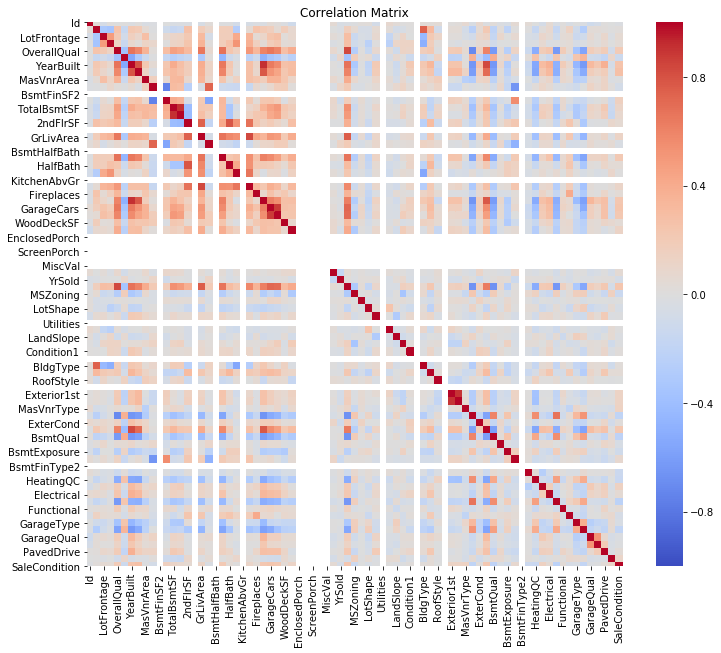

In [19]:
plt.figure(figsize=(12,10))
correlation_matrix = df_lencoder.corr()
sns.heatmap(correlation_matrix, annot=False, cmap="coolwarm", vmin=-1, vmax=1)
plt.title("Correlation Matrix")
plt.show()

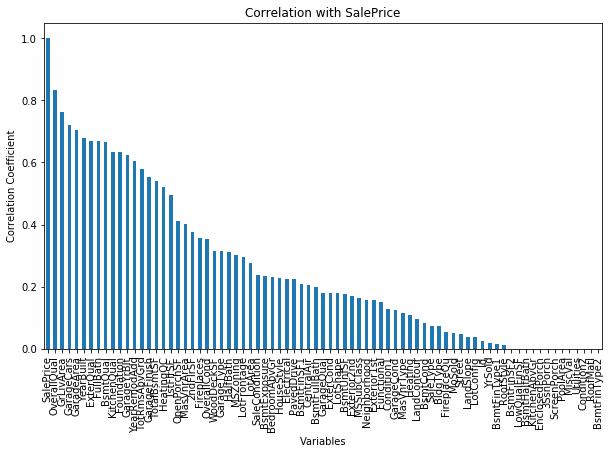

In [20]:
target_corr = df_lencoder.corr()["SalePrice"]
target_corr_sorted = target_corr.abs().sort_values(ascending=False)

plt.figure(figsize=(10,6))
target_corr_sorted.plot(kind="bar")
plt.title("Correlation with SalePrice")
plt.xlabel("Variables")
plt.ylabel("Correlation Coefficient")
plt.show()

## Tahap 3 - Data Splitting

In [21]:
X = df_lencoder.drop(columns=["SalePrice"])
y = df_lencoder["SalePrice"]

X.head()

,Id,MSSubClass,LotFrontage,LotArea,OverallQual,OverallCond,YearBuilt,YearRemodAdd,MasVnrArea,BsmtFinSF1,...,KitchenQual,Functional,FireplaceQu,GarageType,GarageFinish,GarageQual,GarageCond,PavedDrive,SaleType,SaleCondition
0,-1.768952,0.356986,-0.265012,-0.284244,0.614520,-0.523677,0.784193,0.704506,1.183911,0.639427,...,2,4,2,0,1,2,3,2,8,3
2,-1.764179,0.356986,-0.037099,0.744924,0.614520,-0.523677,0.704296,0.653431,0.856804,0.101006,...,2,4,4,0,1,2,3,2,8,3
4,-1.759405,0.356986,1.178437,1.851281,1.419903,-0.523677,0.664347,0.551281,2.665515,0.514611,...,2,4,4,0,1,2,3,2,8,3
6,-1.754632,-0.917637,0.494698,0.316349,1.419903,-0.523677,0.824141,0.806656,1.087703,2.262035,...,2,4,2,0,1,2,3,2,8,3
10,-1.745085,-0.917637,0.114843,0.726546,-0.996245,-0.523677,-0.733845,-1.236347,-0.701766,1.128902,...,3,4,2,3,2,2,3,2,8,3


In [22]:
x_train, x_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=1
)

In [23]:
print("Jumlah data:", len(X))
print("Jumlah data latih:", len(x_train))
print("Jumlah data test:", len(x_test))

Jumlah data: 557
Jumlah data latih: 445
Jumlah data test: 112


## Tahap 4 - Pemilihan Algoritma & Modeling

Target `SalePrice` bersifat kontinu, sehingga kasus ini adalah **regresi**. Tiga algoritma dibandingkan:

- **Linear Regression** - baseline, sederhana dan mudah diinterpretasi.
- **Random Forest Regressor** - ensemble bagging dari banyak pohon, tahan terhadap outlier dan hubungan non-linear.
- **Gradient Boosting Regressor** - ensemble boosting yang memperbaiki error secara bertahap.

Pembagian algoritma menurut jenis tugas:

| Regresi | Klasifikasi |
|---|---|
| Linear, Ridge, Lasso, ElasticNet, Decision Tree Regressor, Random Forest Regressor, Gradient Boosting Regressor, SVR, KNN Regressor (9) | Logistic Regression, KNN Classifier, Naive Bayes, SVM/SVC, Decision Tree Classifier, Random Forest Classifier |

Catatan: Decision Tree, Random Forest, SVM, dan KNN tersedia untuk regresi maupun klasifikasi.

In [24]:
import os, joblib
from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestRegressor, GradientBoostingRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

models = {
    "Linear Regression": LinearRegression(),
    "Random Forest": RandomForestRegressor(n_estimators=200, random_state=1),
    "Gradient Boosting": GradientBoostingRegressor(random_state=1),
}

os.makedirs("models", exist_ok=True)
for name, model in models.items():
    model.fit(x_train, y_train)
    joblib.dump(model, f"models/model_{name.replace(' ', '_')}.joblib")
joblib.dump(scaler, "models/scaler.joblib")
print("Model berhasil dilatih dan disimpan dengan joblib")

Model berhasil dilatih dan disimpan dengan joblib


## Tahap 5 - Evaluasi Model

Pada bagian :

- **MAE, MSE, RMSE** itu rata-rata besar kesalahan prediksi. Nilai semakin kecil (mendekati 0) semakin baik.
- **R2** itu proporsi variasi target yang dijelaskan model. Nilai semakin mendekati 1 semakin baik; R2 = 0 berarti model tidak lebih baik dari rata-rata, dan R2 bisa negatif.

Karena SalePrice ikut distandardisasi, MAE dan RMSE dihitung pada skala terstandardisasi. Kolom USD dikonversi kembali memakai simpangan baku SalePrice dari scaler.

In [25]:
sp_idx = list(numeric_features).index("SalePrice")
sd_price = scaler.scale_[sp_idx]

# Muat ulang model dari file joblib untuk membuktikan penyimpanan berhasil
loaded = {n: joblib.load(f"models/model_{n.replace(' ', '_')}.joblib") for n in models}

rows = {}
for name, model in loaded.items():
    pred = model.predict(x_test)
    rows[name] = {
        "MAE": mean_absolute_error(y_test, pred),
        "MSE": mean_squared_error(y_test, pred),
        "RMSE": np.sqrt(mean_squared_error(y_test, pred)),
        "R2": r2_score(y_test, pred),
        "MAE (USD)": mean_absolute_error(y_test, pred) * sd_price,
        "RMSE (USD)": np.sqrt(mean_squared_error(y_test, pred)) * sd_price,
    }

hasil = pd.DataFrame(rows).T
hasil.round(4)

,MAE,MSE,RMSE,R2,MAE (USD),RMSE (USD)
Linear Regression,0.2350,0.0945,0.3075,0.8822,12976.7227,16976.8248
Random Forest,0.2257,0.0858,0.2930,0.8931,12464.0713,16178.9898
Gradient Boosting,0.2183,0.0903,0.3005,0.8875,12054.5643,16591.7995


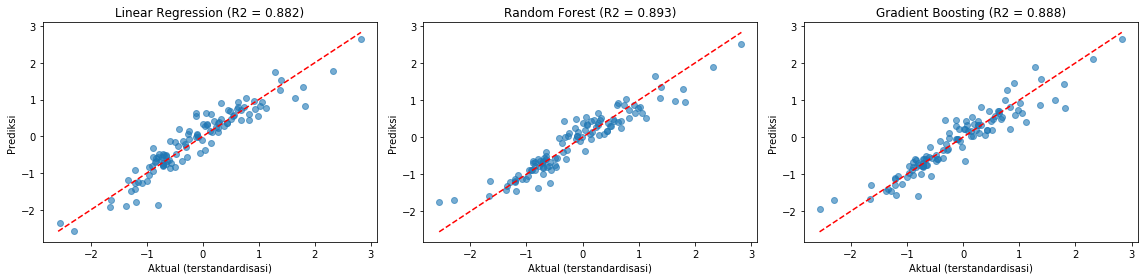

In [26]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4))
for ax, (name, model) in zip(axes, loaded.items()):
    pred = model.predict(x_test)
    ax.scatter(y_test, pred, alpha=0.6)
    lims = [min(y_test.min(), pred.min()), max(y_test.max(), pred.max())]
    ax.plot(lims, lims, "r--")
    ax.set_title(f"{name} (R2 = {r2_score(y_test, pred):.3f})")
    ax.set_xlabel("Aktual (terstandardisasi)")
    ax.set_ylabel("Prediksi")
plt.tight_layout()
plt.show()

### Hasil uji

Pada data uji, MAE berada di kisaran 0,22-0,24 dan RMSE 0,29-0,31 (skala terstandardisasi), jauh lebih dekat ke 0 daripada ke 1. R2 berada di kisaran 0,88-0,89, mendekati 1, sehingga ketiga model tergolong baik. Random Forest memiliki R2 tertinggi dan RMSE terendah, sedangkan Gradient Boosting memiliki MAE terendah. Selisih antar model kecil, sehingga Linear Regression tetap layak sebagai baseline.

Keterbatasan: scaling dilakukan sebelum pembagian data (berpotensi data leakage), LabelEncoder pada kolom nominal menciptakan urutan semu, dan pembuangan outlier IQR menyisakan 557 dari 1.460 baris.


**Evaluasi**

Hodson, T. O. (2022). Root-mean-square error (RMSE) or mean absolute error (MAE): When to use them or not. Geoscientific Model Development, 15(14), 5481-5487. https://doi.org/10.5194/gmd-15-5481-2022
Halaman yang dirujuk: 5481 (rumus MAE dan RMSE, tidak ada satu metrik yang selalu paling baik).

Rainio, O., Teuho, J., & Klen, R. (2024). Evaluation metrics and statistical tests for machine learning. Scientific Reports, 14, 6086. https://doi.org/10.1038/s41598-024-56706-x
Bagian yang dirujuk: Regression (metrik evaluasi untuk prediksi numerik).

Sharma, H., Harsora, H., & Ogunleye, B. (2024). An optimal house price prediction algorithm: XGBoost. Analytics, 3(1), 30-45. https://doi.org/10.3390/analytics3010003
Halaman yang dirujuk:38 (metrik evaluasi, bagian 3.7)

**Pemilihan Algoritma**

Adetunji, A. B., Akande, O. N., Ajala, F. A., Oyewo, O., Akande, Y. F., & Oluwadara, G. (2022). House price prediction using random forest machine learning technique. Procedia Computer Science, 199, 806-813. https://doi.org/10.1016/j.procs.2022.01.100
Halaman yang dirujuk: 806-813 (Random Forest untuk prediksi harga rumah).

Demir, S., & Sahin, E. K. (2023). An investigation of feature selection methods for soil liquefaction prediction based on tree-based ensemble algorithms using AdaBoost, gradient boosting, and XGBoost. Neural Computing and Applications, 35, 3173-3190. https://doi.org/10.1007/s00521-022-07856-4
Halaman yang dirujuk: 3173-3190 (algoritma ensemble berbasis pohon).

James, G., Witten, D., Hastie, T., Tibshirani, R., & Taylor, J. (2023). An introduction to statistical learning: With applications in Python. Springer. https://doi.org/10.1007/978-3-031-38747-0
Halaman yang dirujuk: 69-134 (regresi linear), 201-228 (resampling untuk pemilihan model), 331-366 (metode berbasis pohon).

Sharma, H., Harsora, H., & Ogunleye, B. (2024). An optimal house price prediction algorithm: XGBoost. Analytics, 3(1), 30-45. https://doi.org/10.3390/analytics3010003
Halaman yang dirujuk: 31-32 (regresi dan klasifikasi), 34 (Random Forest), 37 (pemilihan model kandidat), 39-40 (hasil perbandingan model), 42 (kesimpulan).

### Daftar Pustaka

Adetunji, A. B., Akande, O. N., Ajala, F. A., Oyewo, O., Akande, Y. F., & Oluwadara, G. (2022). House price prediction using random forest machine learning technique. Procedia Computer Science, 199, 806-813. https://doi.org/10.1016/j.procs.2022.01.100
Halaman yang dirujuk: 806-813 (Random Forest untuk prediksi harga rumah).

Demir, S., & Sahin, E. K. (2023). An investigation of feature selection methods for soil liquefaction prediction based on tree-based ensemble algorithms using AdaBoost, gradient boosting, and XGBoost. Neural Computing and Applications, 35, 3173-3190. https://doi.org/10.1007/s00521-022-07856-4
Halaman yang dirujuk: 3173-3190 (algoritma ensemble berbasis pohon).

Hjort, A., Pensar, J., Scheel, I., & Sommervoll, D. E. (2022). House price prediction with gradient boosted trees under different loss functions. Journal of Property Research, 39(4), 338-364. https://doi.org/10.1080/09599916.2022.2070525
Halaman yang dirujuk: 338-364 (Gradient Boosting untuk prediksi harga rumah).

Hodson, T. O. (2022). Root-mean-square error (RMSE) or mean absolute error (MAE): When to use them or not. Geoscientific Model Development, 15(14), 5481-5487. https://doi.org/10.5194/gmd-15-5481-2022
Halaman yang dirujuk: 5481 (rumus MAE dan RMSE, tidak ada satu metrik yang selalu paling baik).

James, G., Witten, D., Hastie, T., Tibshirani, R., & Taylor, J. (2023). An introduction to statistical learning: With applications in Python. Springer. https://doi.org/10.1007/978-3-031-38747-0
Halaman yang dirujuk: 69-134 (regresi linear), 201-228 (resampling untuk pemilihan model), 331-366 (metode berbasis pohon).

Plevris, V., Solorzano, G., Bakas, N. P., & Ben Seghier, M. E. A. (2022). Investigation of performance metrics in regression analysis and machine learning-based prediction models. 8th European Congress on Computational Methods in Applied Sciences and Engineering (ECCOMAS Congress 2022).
Bagian yang dirujuk: metrik RMSE, MAE, dan koefisien determinasi (R2).

Rainio, O., Teuho, J., & Klen, R. (2024). Evaluation metrics and statistical tests for machine learning. Scientific Reports, 14, 6086. https://doi.org/10.1038/s41598-024-56706-x
Bagian yang dirujuk: Regression (metrik evaluasi untuk prediksi numerik).

Sharma, H., Harsora, H., & Ogunleye, B. (2024). An optimal house price prediction algorithm: XGBoost. Analytics, 3(1), 30-45. https://doi.org/10.3390/analytics3010003
Halaman yang dirujuk: 31-32 (regresi dan klasifikasi), 34 (Random Forest), 37 (pemilihan model kandidat), 38 (metrik evaluasi, bagian 3.7), 39-40 (hasil perbandingan model), 42 (kesimpulan).